# Comparaison des sources de bâtiments sur des patches So2Sat-LCZ42

**Objectif.** Pour décrire un patch So2Sat (un carré de 320 m) en texte, on a besoin d'informations
sur ses bâtiments : où ils sont, quelle surface ils couvrent, quelle hauteur ils ont.
Plusieurs jeux de données ouverts existent ; ce notebook les compare sur trois lieux test
très différents : un centre ancien européen, un centre d'affaires africain et un quartier informel.

| Source | Couverture | Contenu | Accès | Licence |
|---|---|---|---|---|
| **OSM** | monde | polygones saisis par des contributeurs ; hauteur ou étages parfois | API OSM | ODbL |
| **EUBUCCO v0.2** | Europe | polygones (souvent cadastraux) + hauteur, type, année | Parquet distant (DuckDB) | ODbL |
| **Microsoft Global ML Building Footprints** | monde | polygones détectés sur images ; hauteur parfois | tuiles .csv.gz | ODbL |
| **GlobalBuildingAtlas (TUM)** | monde | polygones fusionnés (OSM, Microsoft, Google) + hauteur estimée pour chacun | Google Earth Engine | ODbL (polygones) |
| **Open Buildings 2.5D Temporal (Google)** | Afrique, Asie du Sud, Amérique latine | **raster** annuel 2016-2023 : présence, hauteur, nombre | Google Earth Engine | CC BY 4.0 / ODbL |

Chaque source a son script d'accès dans ce dossier (`demo_*_patch.py`) ; ce notebook les appelle
et calcule pour toutes **les mêmes indicateurs**. Comme pour les LCZ, on raisonne en **surfaces**
(part du patch couverte de bâtiments, répartition des hauteurs en surface) plutôt qu'en nombre d'objets.

In [1]:
import math
import urllib.request
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from shapely.geometry import LineString, Polygon, box
from shapely.ops import polygonize

from demo_osm_patch import COTE_M, EXEMPLES, emprise
from demo_eubucco_patch import batiments_eubucco, region_nuts
from demo_microsoft_patch import batiments_microsoft
from demo_gba_patch import batiments_gba
from demo_openbuildings_temporal_patch import (carte_hauteurs, couvre, evolution,
                                               indicateurs_openbuildings)

DOSSIER_RESULTATS = Path("resultats")
DOSSIER_RESULTATS.mkdir(exist_ok=True)
pd.set_option("display.width", 200)

## 1. Les trois patches de test

Chaque lieu est un point central ; `emprise()` en fait un carré de 320 m de côté
(32 pixels Sentinel-2 de 10 m), comme un patch So2Sat.

In [2]:
pd.DataFrame(
    [(nom, lat, lon, *(round(x, 5) for x in emprise(lat, lon))) for nom, lat, lon in EXEMPLES],
    columns=["lieu", "lat", "lon", "sud", "ouest", "nord", "est"],
)

,lieu,lat,lon,sud,ouest,nord,est
0,Paris - Quartier latin,48.8535,2.3462,48.85206,2.34402,48.85494,2.34838
1,Nairobi - centre,-1.2850,36.8230,-1.28644,36.82156,-1.28356,36.82444
2,Nairobi - Kibera,-1.3125,36.7865,-1.31394,36.78506,-1.31106,36.78794


## 2. Un format commun et des indicateurs communs

Les scripts d'accès en polygones (OSM, EUBUCCO, Microsoft, GBA) renvoient tous la même chose :
une liste de bâtiments `{"geometrie": polygone en lon/lat découpé au carré, "hauteur_m": float ou None}`.
On peut donc calculer les mêmes indicateurs pour tous :

- **nombre de bâtiments** (à prendre avec prudence : une source peut fusionner un îlot entier) ;
- **surface bâtie** en % du patch : la surface de l'union des emprises, pour ne pas compter deux fois les chevauchements ;
- **surface moyenne** d'un bâtiment ;
- **part de la surface bâtie dont la hauteur est connue** ;
- **hauteur médiane** ;
- **répartition de la surface bâtie en classes de hauteur**, avec les seuils des LCZ (Stewart et Oke, 2012) :
  bas < 10 m, moyen 10-25 m, haut > 25 m.

Pour mesurer des surfaces, on passe les coordonnées en mètres autour du centre du patch
(même approximation que `emprise()` : largement assez précise sur 320 m).

In [3]:
HAUTEUR_PAR_ETAGE_M = 3
CLASSES = ["bas", "moyen", "haut"]
SEUILS_M = [10, 25]


def en_metres(geometrie, lat0, lon0):
    """Passe une géométrie lon/lat en mètres autour du point (lat0, lon0)."""
    def projeter(coords):
        x = (coords[:, 0] - lon0) * 111_320 * math.cos(math.radians(lat0))
        y = (coords[:, 1] - lat0) * 111_320
        return np.column_stack([x, y])
    return shapely.transform(geometrie, projeter)


def classe_hauteur(h):
    """bas / moyen / haut, ou None si la hauteur est inconnue."""
    if h is None:
        return None
    if h < SEUILS_M[0]:
        return "bas"
    if h < SEUILS_M[1]:
        return "moyen"
    return "haut"


def indicateurs(batiments, lat0, lon0):
    """Indicateurs d'une source en polygones sur un patch."""
    for b in batiments:
        b["geometrie_m"] = en_metres(b["geometrie"], lat0, lon0)
        b["surface_m2"] = b["geometrie_m"].area
        b["classe"] = classe_hauteur(b["hauteur_m"])

    surface_batie = shapely.union_all([b["geometrie_m"] for b in batiments]).area if batiments else 0
    surface_totale = sum(b["surface_m2"] for b in batiments)
    avec_hauteur = [b for b in batiments if b["classe"] is not None]
    surface_avec_hauteur = sum(b["surface_m2"] for b in avec_hauteur)
    hauteurs = sorted(b["hauteur_m"] for b in avec_hauteur)

    resultat = {
        "nb_batiments": len(batiments),
        "surface_batie_pct": round(100 * surface_batie / COTE_M ** 2, 1),
        "surface_moyenne_m2": round(surface_totale / len(batiments)) if batiments else None,
        "hauteur_connue_pct_surface": round(100 * surface_avec_hauteur / surface_totale, 1) if batiments else None,
        "hauteur_mediane_m": round(hauteurs[len(hauteurs) // 2], 1) if hauteurs else None,
    }
    for classe in CLASSES:
        surface_classe = sum(b["surface_m2"] for b in avec_hauteur if b["classe"] == classe)
        resultat[f"{classe}_pct"] = round(100 * surface_classe / surface_avec_hauteur, 1) if avec_hauteur else None
    return resultat

## 3. OSM avec les géométries

Le script `demo_osm_patch.py` ne garde que les tags OSM. Pour mesurer des surfaces, il faut
reconstruire les polygones à partir de la réponse de l'API OSM :

- les **ways fermés** tagués `building` (le cas courant) ;
- les **relations multipolygones** taguées `building` : un contour fait de plusieurs ways, avec parfois
  des cours intérieures. Elles sont fréquentes pour les grands bâtiments parisiens (Palais de Justice,
  Hôtel-Dieu) : sans elles, la surface bâtie de Paris tombe de 35 % à 16 %.

La hauteur vient du tag `height`, sinon de `building:levels` × 3 m.

In [4]:
def hauteur_osm(tags):
    """Le tag height, sinon building:levels x 3 m, sinon None."""
    for cle, facteur in (("height", 1), ("building:levels", HAUTEUR_PAR_ETAGE_M)):
        valeur = tags.get(cle, "").replace("m", "").replace(",", ".").strip()
        try:
            return float(valeur) * facteur
        except ValueError:        # tag absent ou mal rempli (ex : "3;4")
            continue
    return None


def batiments_osm(bbox):
    """Bâtiments OSM du carré, au format commun."""
    s, w, n, e = bbox
    url = f"https://api.openstreetmap.org/api/0.6/map?bbox={w},{s},{e},{n}"
    requete = urllib.request.Request(url, headers={"User-Agent": "demo-pfe-lcz"})
    with urllib.request.urlopen(requete, timeout=60) as reponse:
        racine = ET.fromstring(reponse.read())

    # Coordonnées des nœuds, puis tracé et tags de chaque way
    noeuds = {nd.get("id"): (float(nd.get("lon")), float(nd.get("lat"))) for nd in racine.iter("node")}
    traces, tags_des_ways = {}, {}
    for way in racine.iter("way"):
        refs = [nd.get("ref") for nd in way.findall("nd")]
        if all(r in noeuds for r in refs):
            traces[way.get("id")] = [noeuds[r] for r in refs]
            tags_des_ways[way.get("id")] = {t.get("k"): t.get("v") for t in way.findall("tag")}

    candidats = []      # (polygone, tags)

    # a) Les ways fermés tagués "building"
    for id_way, trace in traces.items():
        tags = tags_des_ways[id_way]
        if tags.get("building", "no") != "no" and len(trace) >= 4 and trace[0] == trace[-1]:
            candidats.append((Polygon(trace), tags))

    # b) Les relations multipolygones : on recolle les morceaux de contour, puis on retire les trous
    for relation in racine.iter("relation"):
        tags = {t.get("k"): t.get("v") for t in relation.findall("tag")}
        if tags.get("type") != "multipolygon" or tags.get("building", "no") == "no":
            continue
        morceaux = {"outer": [], "inner": []}
        for membre in relation.findall("member"):
            if membre.get("type") == "way" and membre.get("ref") in traces and membre.get("role") in morceaux:
                morceaux[membre.get("role")].append(LineString(traces[membre.get("ref")]))
        exterieur = shapely.union_all(list(polygonize(morceaux["outer"])))
        trous = shapely.union_all(list(polygonize(morceaux["inner"])))
        if not exterieur.is_empty:
            candidats.append((exterieur.difference(trous), tags))

    # Découpage au carré du patch
    carre = box(w, s, e, n)
    batiments = []
    for polygone, tags in candidats:
        if not polygone.is_valid:
            polygone = polygone.buffer(0)
        if polygone.intersects(carre):
            batiments.append({"geometrie": polygone.intersection(carre), "hauteur_m": hauteur_osm(tags)})
    return batiments

## 4. Récupération des cinq sources

Pour chaque lieu et chaque source, on garde ce qu'il faut pour la figure (les polygones,
ou la carte raster pour Open Buildings) et les indicateurs. `None` signifie « hors couverture » :
EUBUCCO ne couvre que l'Europe, Open Buildings ne couvre pas l'Europe.

Durée : environ une minute par lieu. La première exécution télécharge aussi les tuiles Microsoft
(environ 100 Mo chacune, gardées ensuite dans `cache/microsoft/`).

In [5]:
SOURCES = ["OSM", "EUBUCCO", "Microsoft", "GBA", "Open Buildings 2.5D"]
resultats = {}      # lieu -> source -> (dessin, indicateurs) ; (None, None) = hors couverture

for nom, lat, lon in EXEMPLES:
    print(f"{nom} ...")
    bbox = emprise(lat, lon)
    nuts = region_nuts(nom)
    polygones = {
        "OSM": batiments_osm(bbox),
        "EUBUCCO": batiments_eubucco(bbox, nuts) if nuts else None,
        "Microsoft": batiments_microsoft(bbox),
        "GBA": batiments_gba(bbox),
    }
    resultats[nom] = {source: (batiments, indicateurs(batiments, lat, lon) if batiments is not None else None)
                      for source, batiments in polygones.items()}

    # Open Buildings est un raster : ses indicateurs sont calculés sur les pixels, dans Earth Engine
    if couvre(bbox):
        resultats[nom]["Open Buildings 2.5D"] = (carte_hauteurs(bbox), indicateurs_openbuildings(bbox))
    else:
        resultats[nom]["Open Buildings 2.5D"] = (None, None)

Paris - Quartier latin ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Nairobi - centre ...


Nairobi - Kibera ...


## 5. Tableau comparatif

Une ligne par lieu et par source. Les cases vides correspondent aux sources hors couverture.
Pour Open Buildings, l'année retenue est 2023 et un pixel est « bâti » si la confiance
`building_presence` dépasse 0,5 (seuil arbitraire : la confiance n'est pas calibrée).

In [6]:
tableau = pd.DataFrame([
    {"lieu": lieu, "source": source, **(ind or {})}
    for lieu, par_source in resultats.items()
    for source, (_, ind) in par_source.items()
])
tableau.to_csv(DOSSIER_RESULTATS / "comparaison_sources.csv", index=False)
tableau.set_index(["lieu", "source"])

nb_batiments  surface_batie_pct  surface_moyenne_m2  hauteur_connue_pct_surface  hauteur_mediane_m  bas_pct  moyen_pct  haut_pct
lieu                   source                                                                                                                                               
Paris - Quartier latin OSM                         161.0               34.7               221.0                        89.5               15.0      6.3       93.7       0.0
                       EUBUCCO                     198.0               35.0               181.0                       100.0               16.8      8.2       91.8       0.0
                       Microsoft                    21.0               38.5              1877.0                        99.6               14.0      0.6       99.4       0.0
                       GBA                         166.0               35.0               216.0                       100.0               13.5      2.4       97.6       0.0
                       Open Buildings 2.5D           NaN                NaN                 NaN                         NaN                NaN      NaN        NaN       NaN
Nairobi - centre       OSM                          61.0               37.6               632.0                        41.0               24.0     11.3       44.8      43.9
                       EUBUCCO                       NaN                NaN                 NaN                         NaN                NaN      NaN        NaN       NaN
                       Microsoft                    34.0               42.8              1289.0                         0.0                NaN      NaN        NaN       NaN
                       GBA                          92.0               34.4               384.0                       100.0                8.4     46.5       48.4       5.1
                       Open Buildings 2.5D         180.0               34.3               195.0                       100.0               21.7     13.7       40.8      45.5
Nairobi - Kibera       OSM                         583.0               48.0                84.0                         4.2                3.0    100.0        0.0       0.0
                       EUBUCCO                       NaN                NaN                 NaN                         NaN                NaN      NaN        NaN       NaN
                       Microsoft                   394.0               45.7               119.0                         0.0                NaN      NaN        NaN       NaN
                       GBA                         713.0               58.6                85.0                       100.0                3.5    100.0        0.0       0.0
                       Open Buildings 2.5D         880.0               37.0                43.0                       100.0                5.5     99.9        0.1       0.0

## 6. Figure : ce que voit chaque source

Une ligne par lieu, une colonne par source. Les bâtiments sont colorés par classe de hauteur
(une seule teinte, du clair au foncé : bas, moyen, haut ; gris = hauteur inconnue).
Open Buildings est un raster de 2 m par pixel : ses contours sont donc moins nets.

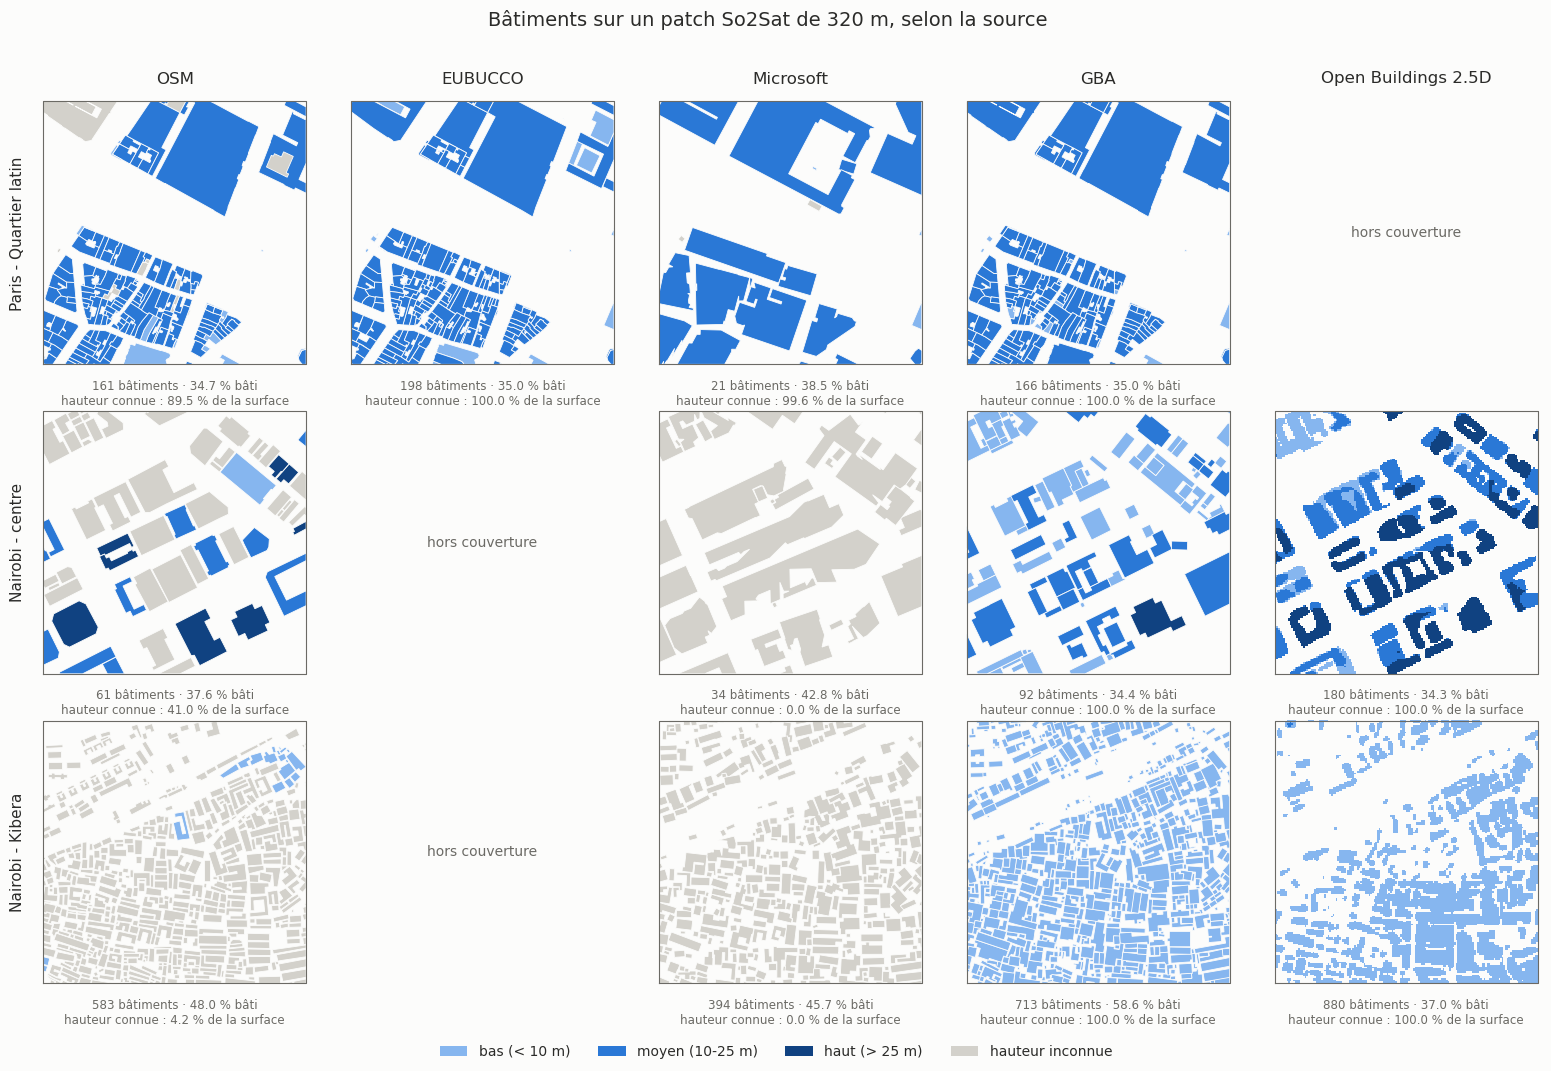

In [7]:
COULEURS = {"bas": "#86b6ef", "moyen": "#2a78d6", "haut": "#104281", None: "#d3d1cb"}
FOND, ENCRE, ENCRE_DOUCE = "#fcfcfb", "#2b2b29", "#6b6a65"
DEMI = COTE_M / 2


def dessiner_polygones(ax, batiments):
    for b in batiments:
        for poly in getattr(b["geometrie_m"], "geoms", [b["geometrie_m"]]):    # MultiPolygon -> morceaux
            if poly.geom_type == "Polygon" and not poly.is_empty:
                x, y = poly.exterior.xy
                ax.fill(x, y, facecolor=COULEURS[b["classe"]], edgecolor=FOND, linewidth=0.6)


def dessiner_raster(ax, classes):
    # 0 = non bâti (transparent), 1 = bas, 2 = moyen, 3 = haut
    palette = ListedColormap([(0, 0, 0, 0), COULEURS["bas"], COULEURS["moyen"], COULEURS["haut"]])
    ax.imshow(classes, cmap=palette, vmin=0, vmax=3, extent=(-DEMI, DEMI, -DEMI, DEMI),
              interpolation="nearest")


fig, axes = plt.subplots(len(resultats), len(SOURCES), figsize=(3.2 * len(SOURCES), 3.6 * len(resultats)),
                         facecolor=FOND)
for i, (lieu, par_source) in enumerate(resultats.items()):
    for j, source in enumerate(SOURCES):
        ax = axes[i][j]
        dessin, ind = par_source[source]
        ax.axis("off")
        if i == 0:
            ax.set_title(source, fontsize=12, color=ENCRE, pad=10)
        if j == 0:
            ax.text(-0.08, 0.5, lieu, rotation=90, ha="center", va="center", transform=ax.transAxes,
                    fontsize=11, color=ENCRE)
        if ind is None:
            ax.text(0.5, 0.5, "hors couverture", ha="center", va="center", color=ENCRE_DOUCE,
                    transform=ax.transAxes, fontsize=10)
            continue
        if isinstance(dessin, np.ndarray):
            dessiner_raster(ax, dessin)
        else:
            dessiner_polygones(ax, dessin)
        ax.plot([-DEMI, DEMI, DEMI, -DEMI, -DEMI], [-DEMI, -DEMI, DEMI, DEMI, -DEMI],
                color=ENCRE_DOUCE, linewidth=0.8)
        ax.set_xlim(-DEMI - 5, DEMI + 5)
        ax.set_ylim(-DEMI - 5, DEMI + 5)
        ax.set_aspect("equal")
        ax.text(0.5, -0.04,
                f"{ind['nb_batiments']} bâtiments · {ind['surface_batie_pct']} % bâti\n"
                f"hauteur connue : {ind['hauteur_connue_pct_surface']} % de la surface",
                ha="center", va="top", transform=ax.transAxes, fontsize=8.5, color=ENCRE_DOUCE)

legende = [Patch(facecolor=COULEURS["bas"], label="bas (< 10 m)"),
           Patch(facecolor=COULEURS["moyen"], label="moyen (10-25 m)"),
           Patch(facecolor=COULEURS["haut"], label="haut (> 25 m)"),
           Patch(facecolor=COULEURS[None], label="hauteur inconnue")]
fig.legend(handles=legende, loc="lower center", ncol=4, frameon=False, fontsize=10, labelcolor=ENCRE)
fig.suptitle(f"Bâtiments sur un patch So2Sat de {COTE_M} m, selon la source", fontsize=14, color=ENCRE)
fig.tight_layout(rect=(0.02, 0.04, 1, 0.97))
fig.savefig(DOSSIER_RESULTATS / "comparaison_sources.png", dpi=150, facecolor=FOND)
plt.show()

## 7. Open Buildings 2.5D : l'évolution 2016-2023

C'est la particularité de ce jeu de données : une estimation par an, à partir d'images Sentinel-2.
On regarde la surface bâtie année par année sur les deux lieux couverts.

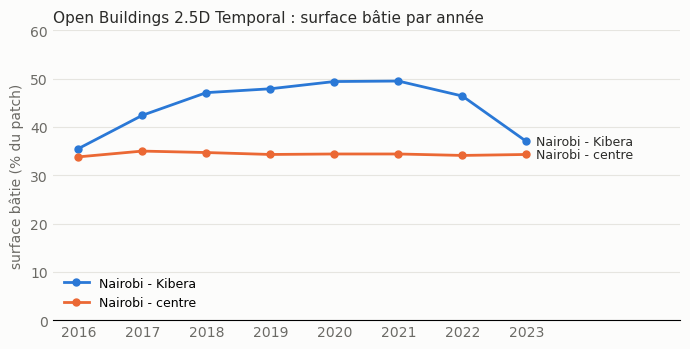

surface_batie_pct                      nb_batiments                 
lieu   Nairobi - Kibera Nairobi - centre Nairobi - Kibera Nairobi - centre
annee                                                                     
2016               35.5             33.8            896.0            131.0
2017               42.4             35.0            903.0            125.0
2018               47.1             34.7           1028.0            137.0
2019               47.9             34.3            908.0            126.0
2020               49.4             34.4            990.0            138.0
2021               49.5             34.4            878.0            140.0
2022               46.4             34.1           1004.0            174.0
2023               37.0             34.3            880.0            180.0

In [8]:
lignes = []
for nom, lat, lon in EXEMPLES:
    bbox = emprise(lat, lon)
    if couvre(bbox):
        lignes += [{"lieu": nom, **l} for l in evolution(bbox)]
temporel = pd.DataFrame(lignes)

fig, ax = plt.subplots(figsize=(7, 3.6), facecolor=FOND)
for (lieu, groupe), couleur in zip(temporel.groupby("lieu"), ["#2a78d6", "#eb6834"]):
    ax.plot(groupe["annee"], groupe["surface_batie_pct"], color=couleur, linewidth=2, marker="o", markersize=5,
            label=lieu)
    ax.text(groupe["annee"].iloc[-1] + 0.15, groupe["surface_batie_pct"].iloc[-1], lieu,
            color=ENCRE, va="center", fontsize=9)
ax.set_ylim(0, 60)
ax.set_xlim(2015.6, 2025.4)
ax.set_xticks(range(2016, 2024))
ax.set_ylabel("surface bâtie (% du patch)", color=ENCRE_DOUCE)
ax.set_facecolor(FOND)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=ENCRE_DOUCE, length=0)
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.set_title("Open Buildings 2.5D Temporal : surface bâtie par année", color=ENCRE, fontsize=11, loc="left")
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "openbuildings_evolution.png", dpi=150, facecolor=FOND)
plt.show()
temporel.pivot(index="annee", columns="lieu", values=["surface_batie_pct", "nb_batiments"])

### Attention : 
Google indique que les détections et les hauteurs fluctuent d'une année à l'autre pour un même bâtiment. Une variation faible entre 2017 et 2023 peut donc n'être que du bruit
Mais une différence de quasiment 20% sur de tels chiffres est non négligeable c'est sûrement un véritable signal de changement.

## 8. Dynamic World : les données récentes décrivent-elles encore le patch So2Sat ?

**Le problème.** Les images So2Sat datent d'environ 2017/2018. Les sources de bâtiments sont plus récentes :
OSM est à jour aujourd'hui, GBA a pour référence 2019, etc. Si un patch a changé entre les deux dates
(nouveau quartier, démolition, champ devenu lotissement), le texte généré à partir des données récentes
décrit autre chose que l'image : c'est une mauvaise supervision pour le modèle.

**L'outil.** [Dynamic World](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_DYNAMICWORLD_V1)
classe chaque image Sentinel-2 depuis mi-2015 en 9 classes (eau, arbres, herbe, cultures, bâti, sol nu...)
à 10 m. C'est le même capteur et la même résolution que So2Sat : un patch fait exactement 32 × 32 pixels.
On peut donc comparer le patch **l'année de l'image So2Sat** avec **l'année de chaque source**.

**Trois indicateurs** (fonctions de `demo_dynamicworld_patch.py`) :
- la **part de pixels « bâti »**, avec pour chaque pixel la classe la plus fréquente de l'année ;
- les **pixels qui ont changé de classe** entre les deux années, toutes classes confondues. Cela compte aussi
  pour les LCZ : une végétation qui disparaît change la classe LCZ même sans nouveau bâtiment ;
- la **probabilité moyenne de « bâti »** donnée par le modèle : un indicateur continu.

**Précautions.**
- La classe « bâti » de Dynamic World inclut routes et surfaces imperméables. On compare des
  **évolutions**, pas son niveau avec les surfaces de bâtiments des autres sources.
- En ville dense, tous les pixels sont « bâti » chaque année : la part de bâti plafonne à 100 % et ne voit
  que les changements en bordure de ville.
- La probabilité de bâti dérive un peu d'une année à l'autre, même sans changement réel. Un patch stable
  comme Paris sert de référence de bruit.
- Un **point témoin** (Ruaka nord, une banlieue de Nairobi qui s'urbanise) est ajouté pour vérifier que les indicateurs
  réagissent bien quand un patch change vraiment. Il a été choisi *parce qu'il* change : il ne dit rien de la
  fréquence des changements dans So2Sat.

In [9]:
from demo_dynamicworld_patch import carte_changement, changement, evolution as evolution_dw

# Année des images So2Sat. Le papier (Zhu et al., 2020) ne la donne pas : ce sont des mosaïques
# Sentinel-2 sans nuages, et les données ont été finalisées en 2018. 2017 est l'hypothèse retenue.
ANNEE_SO2SAT = 2017
ANNEE_ACTUELLE = 2025       # dernière année complète de Dynamic World

# Année approximative que décrit chaque source (à affiner) :
DATES_SOURCES = {
    "OSM": 2025,                  # extrait du jour : état actuel de la carte (2025 = dernière année complète)
    "EUBUCCO": 2025,              # v0.2, publiée en 2025 ; les sources d'origine (cadastres) sont plus anciennes
    "Microsoft": 2020,            # images de 2014 à 2024 selon les régions, sans date par bâtiment
    "GBA": 2019,                  # année de référence des images PlanetScope
    "Open Buildings 2.5D": 2023,  # année choisie dans ce notebook
}

# Un patch est « à vérifier » si, entre l'année So2Sat et l'année de la source :
SEUIL_ECART_BATI_PTS = 5          # la part de bâti a bougé de plus de 5 points
SEUIL_PIXELS_CHANGES_PCT = 15     # ou plus de 15 % des pixels ont changé de classe

# Les 3 lieux de test + le témoin
LIEUX_TEMPORELS = EXEMPLES + [("Ruaka nord (témoin)", -1.1960, 36.7760)]

### 8.1 Évolution 2016-2025

Une courbe par lieu ; le trait vertical marque l'année supposée des images So2Sat.

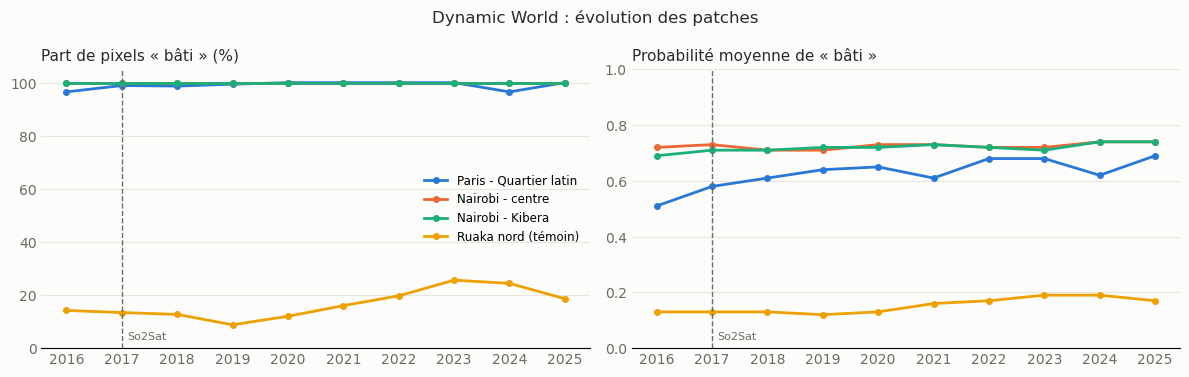

bati_pct                                                                   proba_bati                                                                    nb_images                   \
lieu  Nairobi - Kibera Nairobi - centre Paris - Quartier latin Ruaka nord (témoin) Nairobi - Kibera Nairobi - centre Paris - Quartier latin Ruaka nord (témoin) Nairobi - Kibera Nairobi - centre   
annee                                                                                                                                                                                               
2016             100.0            100.0                   96.5                14.2             0.69             0.72                   0.51                0.13             24.0             24.0   
2017             100.0            100.0                   98.9                13.4             0.71             0.73                   0.58                0.13             21.0             21.0   
2018             100.0            100.0                   98.7                12.7             0.71             0.71                   0.61                0.13             34.0             34.0   
2019             100.0            100.0                   99.4                 8.8             0.72             0.71                   0.64                0.12             29.0             29.0   
2020             100.0            100.0                  100.0                12.0             0.72             0.73                   0.65                0.13             28.0             28.0   
2021             100.0            100.0                  100.0                16.0             0.73             0.73                   0.61                0.16             28.0             28.0   
2022             100.0            100.0                  100.0                19.7             0.72             0.72                   0.68                0.17             32.0             32.0   
2023             100.0            100.0                  100.0                25.6             0.71             0.72                   0.68                0.19             32.0             32.0   
2024             100.0            100.0                   96.5                24.4             0.74             0.74                   0.62                0.19             44.0             44.0   
2025             100.0            100.0                  100.0                18.6             0.74             0.74                   0.69                0.17             49.0             49.0   

                                                  
lieu  Paris - Quartier latin Ruaka nord (témoin)  
annee                                             
2016                    41.0                24.0  
2017                    32.0                21.0  
2018                    58.0                34.0  
2019                    43.0                29.0  
2020                    56.0                28.0  
2021                    38.0                28.0  
2022                    56.0                32.0  
2023                    38.0                32.0  
2024                    28.0                44.0  
2025                    62.0                49.0

In [10]:
lignes = []
for nom, lat, lon in LIEUX_TEMPORELS:
    lignes += [{"lieu": nom, **l} for l in evolution_dw(emprise(lat, lon))]
dw = pd.DataFrame(lignes)

COULEURS_LIEUX = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]     # palette catégorielle, ordre fixe
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), facecolor=FOND)
for ax, colonne, titre, haut in [(axes[0], "bati_pct", "Part de pixels « bâti » (%)", 105),
                                  (axes[1], "proba_bati", "Probabilité moyenne de « bâti »", 1.0)]:
    for (lieu, groupe), couleur in zip(dw.groupby("lieu", sort=False), COULEURS_LIEUX):
        ax.plot(groupe["annee"], groupe[colonne], color=couleur, linewidth=2, marker="o", markersize=4, label=lieu)
    ax.axvline(ANNEE_SO2SAT, color=ENCRE_DOUCE, linewidth=1, linestyle="--")
    ax.text(ANNEE_SO2SAT + 0.1, haut * 0.03, "So2Sat", color=ENCRE_DOUCE, fontsize=8)
    ax.set_ylim(0, haut)
    ax.set_xticks(range(2016, 2026))
    ax.set_title(titre, color=ENCRE, fontsize=11, loc="left")
    ax.set_facecolor(FOND)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(colors=ENCRE_DOUCE, length=0)
axes[0].legend(frameon=False, fontsize=8.5, loc="center right")
fig.suptitle("Dynamic World : évolution des patches", color=ENCRE, fontsize=12)
fig.tight_layout()
fig.savefig(DOSSIER_RESULTATS / "dynamicworld_evolution.png", dpi=150, facecolor=FOND)
plt.show()

dw.pivot(index="annee", columns="lieu", values=["bati_pct", "proba_bati", "nb_images"])

### 8.2 Kibera : Open Buildings et Dynamic World voient-ils la même évolution ?

La partie 7 montre une forte variation de la surface bâtie d'Open Buildings à Kibera. Si c'était un vrai
changement, Dynamic World, qui repose sur les mêmes images Sentinel-2, devrait le voir aussi.

In [11]:
kibera = (temporel[temporel["lieu"] == "Nairobi - Kibera"][["annee", "surface_batie_pct"]]
          .rename(columns={"surface_batie_pct": "Open Buildings : bâti (%)"})
          .merge(dw[dw["lieu"] == "Nairobi - Kibera"][["annee", "bati_pct", "proba_bati"]]
                 .rename(columns={"bati_pct": "Dynamic World : bâti (%)",
                                  "proba_bati": "Dynamic World : probabilité"}),
                 on="annee"))
kibera.set_index("annee")

,Open Buildings : bâti (%),Dynamic World : bâti (%),Dynamic World : probabilité
annee,,,
2016,35.5,100.0,0.69
2017,42.4,100.0,0.71
2018,47.1,100.0,0.71
2019,47.9,100.0,0.72
2020,49.4,100.0,0.72
2021,49.5,100.0,0.73
2022,46.4,100.0,0.72
2023,37.0,100.0,0.71


### 8.3 Tableau de cohérence : peut-on utiliser chaque source pour décrire l'image So2Sat ?

Pour chaque lieu et chaque source, on compare le patch en `ANNEE_SO2SAT` et à l'année de la source.

In [12]:
lignes = []
for nom, lat, lon in LIEUX_TEMPORELS:
    bbox = emprise(lat, lon)
    for source, annee_source in DATES_SOURCES.items():
        c = changement(bbox, ANNEE_SO2SAT, annee_source)
        a_verifier = (abs(c["ecart_bati_pts"]) > SEUIL_ECART_BATI_PTS
                      or c["pixels_changes_pct"] > SEUIL_PIXELS_CHANGES_PCT)
        lignes.append({"lieu": nom, "source": source, "annee_so2sat": ANNEE_SO2SAT,
                       "annee_source": annee_source, **c,
                       "verdict": "à vérifier" if a_verifier else "cohérent"})
coherence = pd.DataFrame(lignes)
coherence.to_csv(DOSSIER_RESULTATS / "coherence_temporelle.csv", index=False)
coherence.set_index(["lieu", "source"])

annee_so2sat  annee_source  ecart_bati_pts  devenus_batis_pct  plus_batis_pct  pixels_changes_pct     verdict
lieu                   source                                                                                                                            
Paris - Quartier latin OSM                          2017          2025             1.1                1.1             0.0                 1.1    cohérent
                       EUBUCCO                      2017          2025             1.1                1.1             0.0                 1.1    cohérent
                       Microsoft                    2017          2020             1.1                1.1             0.0                 1.1    cohérent
                       GBA                          2017          2019             0.5                0.8             0.3                 1.1    cohérent
                       Open Buildings 2.5D          2017          2023             1.1                1.1             0.0                 1.1    cohérent
Nairobi - centre       OSM                          2017          2025             0.0                0.0             0.0                 0.0    cohérent
                       EUBUCCO                      2017          2025             0.0                0.0             0.0                 0.0    cohérent
                       Microsoft                    2017          2020             0.0                0.0             0.0                 0.0    cohérent
                       GBA                          2017          2019             0.0                0.0             0.0                 0.0    cohérent
                       Open Buildings 2.5D          2017          2023             0.0                0.0             0.0                 0.0    cohérent
Nairobi - Kibera       OSM                          2017          2025             0.0                0.0             0.0                 0.0    cohérent
                       EUBUCCO                      2017          2025             0.0                0.0             0.0                 0.0    cohérent
                       Microsoft                    2017          2020             0.0                0.0             0.0                 0.0    cohérent
                       GBA                          2017          2019             0.0                0.0             0.0                 0.0    cohérent
                       Open Buildings 2.5D          2017          2023             0.0                0.0             0.0                 0.0    cohérent
Ruaka nord (témoin)    OSM                          2017          2025             5.2                6.2             1.1                28.1  à vérifier
                       EUBUCCO                      2017          2025             5.2                6.2             1.1                28.1  à vérifier
                       Microsoft                    2017          2020            -1.4                1.3             2.6                 8.3    cohérent
                       GBA                          2017          2019            -4.6                0.0             4.6                 5.9    cohérent
                       Open Buildings 2.5D          2017          2023            12.2               12.3             0.1                14.2  à vérifier

### 8.4 Où le patch a-t-il changé ?

Les changements du bâti entre l'année So2Sat et 2025, pixel par pixel (10 m).

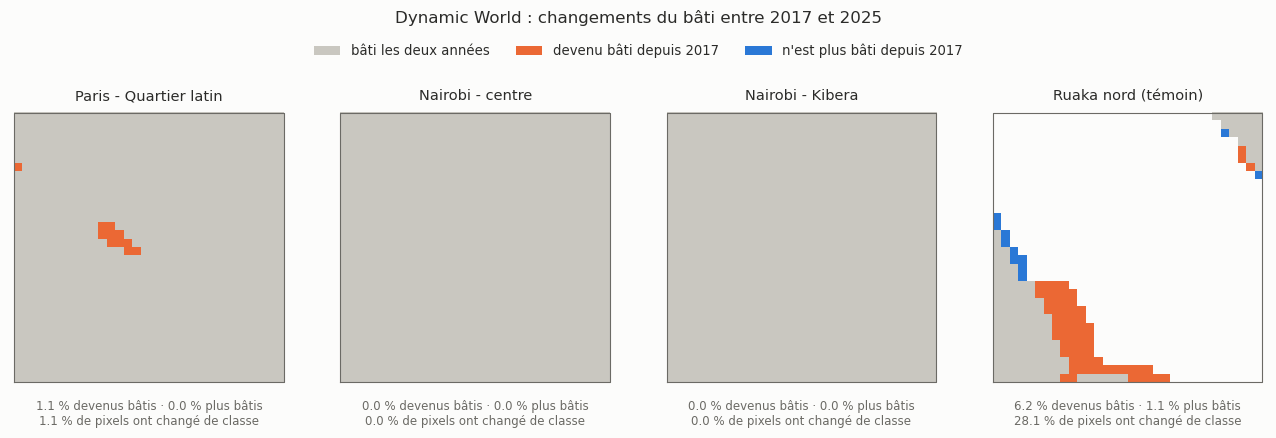

In [13]:
COULEURS_CHANGEMENT = ["#00000000", "#c9c7c0", "#eb6834", "#2a78d6"]
NOMS_CHANGEMENT = ["", "bâti les deux années", f"devenu bâti depuis {ANNEE_SO2SAT}",
                   f"n'est plus bâti depuis {ANNEE_SO2SAT}"]

fig, axes = plt.subplots(1, len(LIEUX_TEMPORELS), figsize=(3.3 * len(LIEUX_TEMPORELS), 4.4), facecolor=FOND)
for ax, (nom, lat, lon) in zip(axes, LIEUX_TEMPORELS):
    bbox = emprise(lat, lon)
    carte = carte_changement(bbox, ANNEE_SO2SAT, ANNEE_ACTUELLE)
    ax.imshow(carte, cmap=ListedColormap(COULEURS_CHANGEMENT), vmin=0, vmax=3,
              extent=(-DEMI, DEMI, -DEMI, DEMI), interpolation="nearest")
    ax.plot([-DEMI, DEMI, DEMI, -DEMI, -DEMI], [-DEMI, -DEMI, DEMI, DEMI, -DEMI], color=ENCRE_DOUCE, linewidth=0.8)
    c = changement(bbox, ANNEE_SO2SAT, ANNEE_ACTUELLE)
    ax.set_title(nom, color=ENCRE, fontsize=10.5)
    ax.text(0.5, -0.05, f"{c['devenus_batis_pct']} % devenus bâtis · {c['plus_batis_pct']} % plus bâtis\n"
                        f"{c['pixels_changes_pct']} % de pixels ont changé de classe",
            ha="center", va="top", transform=ax.transAxes, fontsize=8.5, color=ENCRE_DOUCE)
    ax.set_xlim(-DEMI - 5, DEMI + 5)
    ax.set_ylim(-DEMI - 5, DEMI + 5)
    ax.set_aspect("equal")
    ax.axis("off")
fig.legend(handles=[Patch(facecolor=couleur, label=nom)
                    for couleur, nom in zip(COULEURS_CHANGEMENT[1:], NOMS_CHANGEMENT[1:])],
           loc="upper center", bbox_to_anchor=(0.5, 0.93), ncol=3, frameon=False, fontsize=9.5, labelcolor=ENCRE)
fig.suptitle(f"Dynamic World : changements du bâti entre {ANNEE_SO2SAT} et {ANNEE_ACTUELLE}",
             color=ENCRE, fontsize=12)
fig.tight_layout(rect=(0, 0.09, 1, 0.86))
fig.savefig(DOSSIER_RESULTATS / "dynamicworld_changements.png", dpi=150, facecolor=FOND)
plt.show()

## 9. Observations

Constats sur ces trois patches (exécution du 25 novembre 2026) :

**Surface bâtie : les sources s'accordent assez bien.**
- Paris : 35 % pour OSM, EUBUCCO et GBA, 38,5 % pour Microsoft. Les polygones de GBA à Paris viennent
  presque tous d'OSM (162 sur 166) : les deux colonnes sont donc quasi identiques.
- Nairobi centre : de 34 à 43 % selon la source.
- Kibera : l'écart est plus grand, de 37 % (Open Buildings) à 59 % (GBA). Dans un quartier informel très dense,
  la frontière entre deux toits voisins est difficile à voir, et chaque source tranche différemment.

**Nombre de bâtiments : peu fiable pour comparer.** Microsoft fusionne les îlots parisiens
(21 objets au lieu d'environ 200). Il vaut mieux s'appuyer sur la surface bâtie, comme le prévoient les conventions du projet.

**Hauteur : c'est là que les sources divergent.**
- En Europe, EUBUCCO est la référence : hauteur sur 100 % des bâtiments, issue du cadastre français pour 175 bâtiments sur 198.
  OSM et GBA donnent la même classe (moyen) à Paris.
- À Nairobi centre, OSM (là où les étages sont saisis) et Open Buildings voient environ 45 % de surface « haute »
  (médiane d'environ 22-24 m). **GBA ne voit que 5 % de surface haute (médiane 8,4 m) : il sous-estime nettement
  les tours.** C'est cohérent avec la remarque du CLAUDE.md, qui jugeait GBA peu fiable.
- Microsoft ne donne aucune hauteur au Kenya, et OSM presque aucune à Kibera (4 % de la surface).
- Sur les trois lieux, tout le monde s'accorde à classer Kibera en bâti bas.

**Open Buildings 2.5D Temporal.**
- La surface bâtie de Nairobi centre est stable de 2016 à 2023.
- À Kibera, elle monte de 35 % à 49 % puis redescend à 37 % en 2023. Ces variations sont probablement en partie
  du bruit de l'estimation à partir de Sentinel-2 : il faut être prudent avant d'y lire une évolution réelle.

**Dynamic World : les données récentes décrivent-elles encore l'image So2Sat ?**
- Sur nos 3 patches, oui : entre 2017 et l'année de chaque source, moins de 1,1 % des pixels changent de classe.
  Les 15 lignes du tableau de cohérence sont « cohérentes ».
- Limite importante : en ville dense, Dynamic World classe 100 % des pixels en « bâti » chaque année. Il ne verrait donc pas
  une densification à l'intérieur d'un quartier déjà bâti (immeubles plus hauts, cours construites). Il repère surtout les
  changements en bordure de ville, champ ou friche devenu lotissement : c'est le cas du témoin Ruaka nord
  (+6 % de pixels devenus bâtis, 28 % de pixels qui changent de classe).
- La probabilité de « bâti » dérive à Paris (de 0,51 à 0,69) alors que le quartier n'a pas changé : elle ne suffit pas seule à conclure.
- **Kibera :** la probabilité Dynamic World reste stable de 2016 à 2023 (de 0,69 à 0,73). La forte hausse puis la baisse de la
  surface bâtie d'Open Buildings (de 35 à 49 puis 37 %) n'apparaissent pas dans Dynamic World, qui repose pourtant sur les mêmes images.
  C'est plutôt un argument pour du bruit d'Open Buildings que pour un vrai changement. À confirmer en regardant
  l'historique d'images de Google Earth Pro sur ce patch.
- Le verdict dépend de la date de la source : à Ruaka nord, Microsoft (2020) et GBA (2019) restent « cohérents »,
  mais OSM et EUBUCCO (2025) et Open Buildings (2023) sont « à vérifier ». Pour So2Sat, il vaut mieux prendre la source
  la plus proche de 2017 quand le patch a changé.

**Conclusions avec de nouvelles pistes pour le pipeline.** Pour la surface bâtie : EUBUCCO ou OSM en Europe, OSM, Microsoft ou Open Buildings ailleurs.
Pour la hauteur : EUBUCCO en Europe et Open Buildings 2.5D dans les pays couverts, avec OSM en complément quand il est renseigné.
Ces conclusions ne reposent que sur 3 patches : il faudra les vérifier sur un échantillon plus large.